In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)

n_samples = 1200
districts = [
    'Dibrugarh', 'Tinsukia', 'Jorhat', 'Sibsagar', 'Cachar', 
    'West Tripura', 'South Tripura', 'North Tripura', 'East Khasi Hills', 'Imphal West'
]
crops = ['Tea', 'Natural Rubber']
years = list(range(2012, 2024))

data = []
for _ in range(n_samples):
    district = np.random.choice(districts)
    crop = np.random.choice(crops)
    year = np.random.choice(years)
    
    pre_monsoon_rain = np.random.normal(350, 80)
    monsoon_rain = np.random.normal(1800, 300)
    mean_temp = np.random.normal(24.5, 2.0)
    soil_ph = np.random.normal(5.2, 0.4)
    fertilizer_kg_ha = np.random.uniform(120, 350)
    pesticide_kg_ha = np.random.uniform(1.5, 6.0)
    
    base_yield = 1800 if crop == 'Tea' else 1400
    rain_effect = 0.6 * (monsoon_rain - 1800) - 0.3 * abs(pre_monsoon_rain - 350)
    temp_effect = -40 * (mean_temp - 24.5)**2
    fert_effect = 2.5 * fertilizer_kg_ha
    noise = np.random.normal(0, 150)
    
    yield_kg_ha = max(500, base_yield + rain_effect + temp_effect + fert_effect + noise)
    
    data.append({
        'district': district,
        'crop': crop,
        'year': year,
        'pre_monsoon_rain_mm': round(pre_monsoon_rain, 2),
        'monsoon_rain_mm': round(monsoon_rain, 2),
        'mean_temp_c': round(mean_temp, 2),
        'soil_ph': round(soil_ph, 2),
        'fertilizer_kg_ha': round(fertilizer_kg_ha, 2),
        'pesticide_kg_ha': round(pesticide_kg_ha, 2),
        'yield_kg_ha': round(yield_kg_ha, 2)
    })

df = pd.DataFrame(data)
df.to_csv('ne_crop_data.csv', index=False)
display(df.head())

,district,crop,year,pre_monsoon_rain_mm,monsoon_rain_mm,mean_temp_c,soil_ph,fertilizer_kg_ha,pesticide_kg_ha,yield_kg_ha
0,South Tripura,Natural Rubber,2022,387.91,2210.54,22.67,5.15,225.63,3.00,2123.41
1,Cachar,Natural Rubber,2019,275.67,1659.16,25.59,5.01,189.98,3.86,1651.17
2,East Khasi Hills,Tea,2022,268.97,1894.27,22.68,4.64,224.90,5.03,2272.70
3,East Khasi Hills,Tea,2016,236.02,1454.70,25.25,4.96,277.37,3.48,2185.72
4,South Tripura,Natural Rubber,2019,415.80,1433.75,24.92,4.42,245.74,2.33,1878.66


In [3]:
!pip install "numpy<2" --force-reinstall

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
   -------- ------------------------------- 3.1/15.5 MB 23.1 MB/s eta 0:00:01
   -------- ------------------------------- 3.1/15.5 MB 23.1 MB/s eta 0:00:01
   -------- ------------------------------- 3.4/15.5 MB 5.2 MB/s eta 0:00:03
   ------------- -------------------------- 5.2/15.5 MB 6.8 MB/s eta 0:00:02
   -------------- ------------------------- 5.5/15.5 MB 5.0 MB/s eta 0:00:02
   ----------------------- ---------------- 9.2/15.5 MB 7.2 MB/s eta 0:00:01
   ------------------------ --------------- 9.4/15.5 MB 7.3 MB/s eta 0:00:01
   --------------------------- ------------ 10.5/15.5 MB 6.4 MB/s eta 0:00:01
   -------------------------------- ------- 12.6/15.5 MB 6.6 MB/s eta 0:00:01
   -------------------------------- ------- 12.6/15.5 MB 6.6 MB/s eta 0:00:01
   --------------------------------- ------ 12.8/15.5 MB 5.6 MB/s eta 0:00:01

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.4.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
shap 0.54.1 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('ne_crop_data.csv')
df_encoded = pd.get_dummies(df, columns=['district', 'crop'], drop_first=True)

X = df_encoded.drop(columns=['yield_kg_ha', 'year'])
y = df_encoded['yield_kg_ha']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (960, 16)
Testing set shape: (240, 16)


In [6]:
import optuna
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42
    }
    model = XGBRegressor(**params)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    return np.sqrt(mean_squared_error(y_test, preds))

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=15)

best_params = study.best_params
print(best_params)

{'n_estimators': 240, 'max_depth': 3, 'learning_rate': 0.0430546138245939, 'subsample': 0.7335033885718149, 'colsample_bytree': 0.8997282251454856}


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train.astype(float).values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test.astype(float).values, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

class CropYieldNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

model_nn = CropYieldNN(X_train.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model_nn.parameters(), lr=0.001)

model_nn.train()
for epoch in range(50):
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        preds = model_nn(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()

model_nn.eval()
with torch.no_grad():
    nn_preds = model_nn(X_test_tensor).numpy().flatten()

print(nn_preds[:5])

[1686.7347 2123.191  1940.7562 2090.9788 1645.8557]


In [9]:
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

final_xgb = XGBRegressor(**best_params, random_state=42)
final_xgb.fit(X_train, y_train)
xgb_preds = final_xgb.predict(X_test)

ensemble_preds = 0.5 * xgb_preds + 0.5 * nn_preds

rmse = np.sqrt(mean_squared_error(y_test, ensemble_preds))
print(f"Ensemble RMSE: {rmse:.2f}")

Ensemble RMSE: 227.89


C:\Users\ANURUP\AppData\Local\Temp\ipykernel_10264\282655388.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, plot_type="bar")


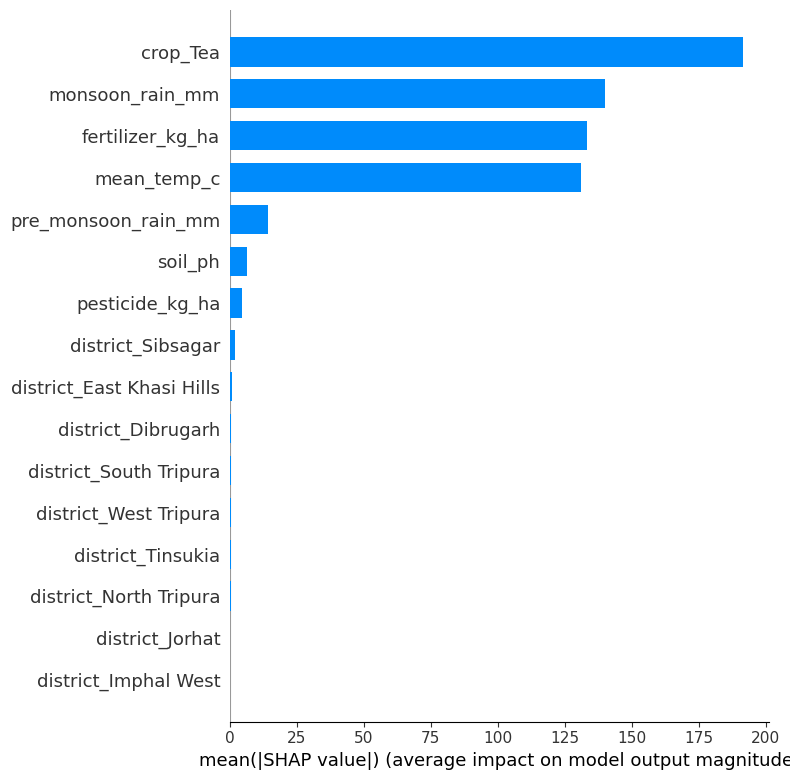

In [10]:
import shap

explainer = shap.Explainer(final_xgb)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test, plot_type="bar")

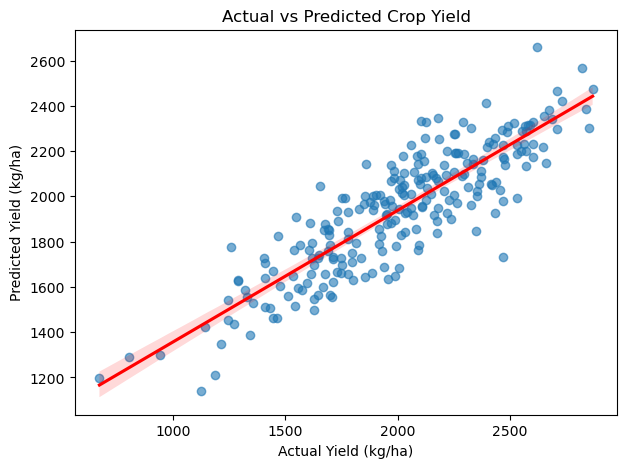

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.regplot(x=y_test, y=ensemble_preds, scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
plt.xlabel('Actual Yield (kg/ha)')
plt.ylabel('Predicted Yield (kg/ha)')
plt.title('Actual vs Predicted Crop Yield')
plt.show()

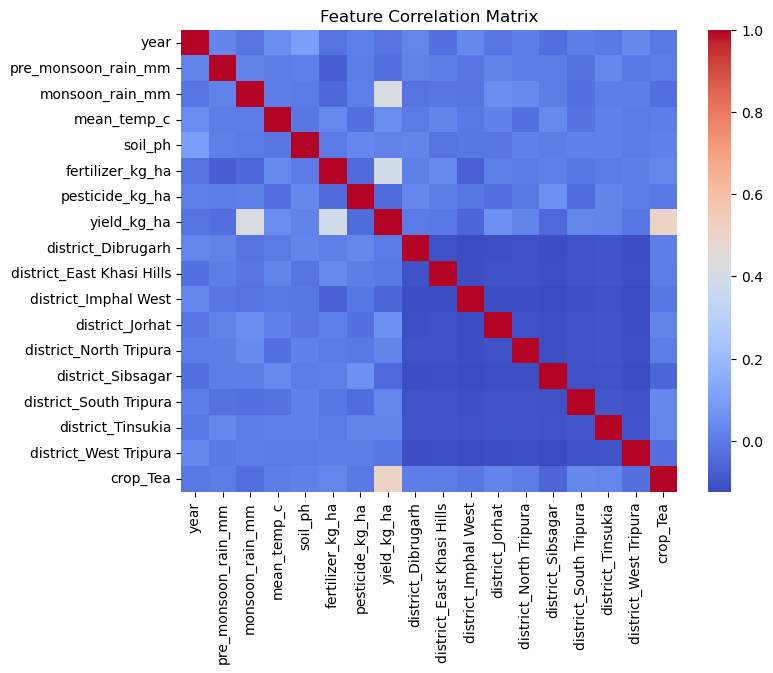

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(df_encoded.corr(), cmap='coolwarm', annot=False)
plt.title('Feature Correlation Matrix')
plt.show()

In [13]:
import os
print(os.getcwd())

C:\Users\ANURUP\ne_crop_ml
